# Ancillary Purchase Prediction & Revenue Optimization
## Will this booking buy an add-on at checkout - travel insurance, a seat upgrade, or extra baggage?

**Business problem.** Ancillaries are high-margin revenue on top of the ticket. At checkout the airline/OTA can show the add-on offer to everyone (costly in promo spend and screen fatigue) or target it. This project predicts, **at the moment the offer would be shown**, the probability that a booking buys at least one ancillary, compares a parametric model (Logistic Regression) with a non-parametric one (Random Forest), calibrates the winner's probabilities, and simulates the revenue of targeting by predicted propensity.

**Data disclosure.** Real ancillary-purchase data is not public. The dataset (60,000 bookings, Jan-Jun 2026) is synthetic: bookings are simulated with realistic distributions and each purchase is drawn from an explicit logistic propensity model documented in `src/generate_data.py`, so the signal is real and recoverable but no number here is a claim about a real airline. Features use only what is known at checkout, before the offer - see the leakage audit in section 4.

## 1. Load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss
from sklearn.inspection import permutation_importance

DATA = Path("../data")
REPORTS = Path("../reports")
REPORTS.mkdir(exist_ok=True)

bookings = pd.read_csv(DATA / "bookings.csv", parse_dates=["booking_date"])
customers = pd.read_csv(DATA / "customers.csv")
print("bookings:", bookings.shape, "| customers:", customers.shape)
bookings.head(3)

bookings: (60000, 23) | customers: (34000, 4)


,booking_id,customer_id,booking_date,route_type,destination_region,trip_purpose,cabin,flight_duration_hrs,lead_time_days,party_size,...,device,loyalty_tier,departure_weekend,prior_trips,prior_ancillary_buyer,bought_insurance,bought_seat_upgrade,bought_extra_baggage,purchased_ancillary,ancillary_revenue_usd
0,B000024,C01268,2026-01-01,Domestic,Europe,Leisure,Economy,1.0,146,1,...,Desktop,Basic,0,0,0,0,0,0,0,0
1,B000146,C23665,2026-01-01,Domestic,East Asia,Leisure,Economy,1.4,116,3,...,Desktop,Basic,0,0,0,0,0,0,0,0
2,B000178,C18228,2026-01-01,International,Middle East,Leisure,Economy,5.5,160,2,...,Mobile,Silver,0,0,0,0,0,0,0,0


## 2. Data understanding

In [2]:
bookings.dtypes

booking_id                          str
customer_id                         str
booking_date             datetime64[us]
route_type                          str
destination_region                  str
trip_purpose                        str
cabin                               str
flight_duration_hrs             float64
lead_time_days                    int64
party_size                        int64
has_children                      int64
fare_usd                        float64
channel                             str
device                              str
loyalty_tier                        str
departure_weekend                 int64
prior_trips                       int64
prior_ancillary_buyer             int64
bought_insurance                  int64
bought_seat_upgrade               int64
bought_extra_baggage              int64
purchased_ancillary               int64
ancillary_revenue_usd             int64
dtype: object

In [3]:
bookings.describe(include="all").T.head(25)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
booking_id,60000,60000,B000024,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,60000,28172,C26026,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booking_date,60000,NaN,NaN,NaN,2026-03-31 12:38:52.800000,2026-01-01 00:00:00,2026-02-15 00:00:00,2026-03-31 00:00:00,2026-05-16 00:00:00,2026-06-29 00:00:00,NaN
route_type,60000,2,Domestic,37165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_region,60000,6,Middle East,10118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trip_purpose,60000,2,Leisure,42703,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cabin,60000,3,Economy,50504,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight_duration_hrs,60000.0,NaN,NaN,NaN,4.092708,0.8,1.9,3.0,6.1,11.0,2.884997
lead_time_days,60000.0,NaN,NaN,NaN,89.96645,0.0,45.0,90.0,135.0,180.0,52.189045
party_size,60000.0,NaN,NaN,NaN,1.871917,1.0,1.0,2.0,2.0,5.0,1.048346


In [4]:
print("booking window:", bookings["booking_date"].min().date(), "to", bookings["booking_date"].max().date())
print("unique customers in bookings:", bookings["customer_id"].nunique())
print("repeat customers make the history features possible - and make a random split leaky (section 5).")

booking window: 2026-01-01 to 2026-06-29
unique customers in bookings: 28172
repeat customers make the history features possible - and make a random split leaky (section 5).


## 3. Data quality checks (the same checks as `sql/01_data_quality.sql`)

In [5]:
checks = {
    "one row per booking": bookings["booking_id"].is_unique,
    "no orphan customers": bookings["customer_id"].isin(customers["customer_id"]).all(),
    "label = any of the 3 products": (bookings["purchased_ancillary"] ==
        ((bookings[["bought_insurance", "bought_seat_upgrade", "bought_extra_baggage"]].sum(axis=1) > 0).astype(int))).all(),
    "revenue 0 iff nothing bought": (((bookings["purchased_ancillary"] == 0) & (bookings["ancillary_revenue_usd"] == 0)) |
        ((bookings["purchased_ancillary"] == 1) & (bookings["ancillary_revenue_usd"] > 0))).all(),
    "no seat upgrades sold into Business cabin": not ((bookings["cabin"] == "Business") & (bookings["bought_seat_upgrade"] == 1)).any(),
    "no nulls in features or label": not bookings[["fare_usd", "lead_time_days", "purchased_ancillary"]].isna().any().any(),
}
for name, ok in checks.items():
    print(("PASS" if ok else "FAIL"), "-", name)
assert all(checks.values())

PASS - one row per booking
PASS - no orphan customers
PASS - label = any of the 3 products
PASS - revenue 0 iff nothing bought
PASS - no seat upgrades sold into Business cabin
PASS - no nulls in features or label


## 4. Leakage audit - what the model may and may not see
Prediction point: **checkout, before the ancillary offer is shown.**

Features (known at that moment): route, trip purpose, cabin, duration, lead time, party, children, fare, channel, device, loyalty tier, departure weekend, and the customer's own history **up to this booking** (`prior_trips`, `prior_ancillary_buyer` - recomputed in `sql/02_analysis_table.sql` from earlier bookings only; a test proves both versions match exactly).

Excluded: `bought_insurance / bought_seat_upgrade / bought_extra_baggage` (they ARE the outcome), `ancillary_revenue_usd` (recorded after the decision), and the generator's latent traveller trait (never stored in the data).

In [6]:
FEATURES = ["route_type", "destination_region", "trip_purpose", "cabin", "flight_duration_hrs",
            "lead_time_days", "party_size", "has_children", "fare_usd", "channel", "device",
            "loyalty_tier", "departure_weekend", "prior_trips", "prior_ancillary_buyer"]
TARGET = "purchased_ancillary"
EXCLUDED = ["bought_insurance", "bought_seat_upgrade", "bought_extra_baggage", "ancillary_revenue_usd"]
print("features:", len(FEATURES), "| excluded as leakage:", EXCLUDED)

features: 15 | excluded as leakage: ['bought_insurance', 'bought_seat_upgrade', 'bought_extra_baggage', 'ancillary_revenue_usd']


## 5. Exploratory analysis - where does ancillary buying happen?

In [7]:
take = bookings.groupby("purchased_ancillary").size()
print("overall take rate:", round(bookings[TARGET].mean() * 100, 2), "%  | buyers:", int(bookings[TARGET].sum()))
for col in ["bought_insurance", "bought_seat_upgrade", "bought_extra_baggage"]:
    print(f"  {col:22s} {bookings[col].mean() * 100:5.2f}%")

overall take rate: 38.71 %  | buyers: 23224
  bought_insurance       17.07%
  bought_seat_upgrade    14.06%
  bought_extra_baggage   16.52%


In [8]:
seg = bookings.groupby(["route_type", "trip_purpose"])[TARGET].mean().mul(100).round(2).unstack()
seg

trip_purpose,Business,Leisure
route_type,,
Domestic,30.21,32.60
International,49.69,49.79


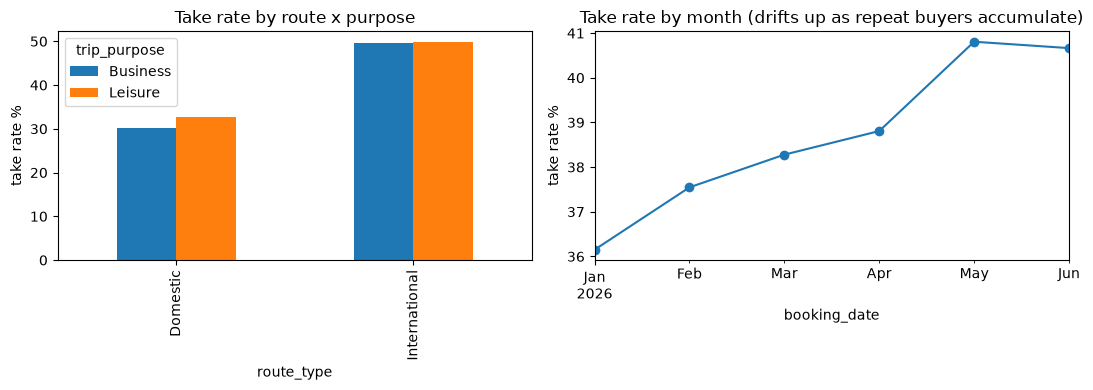

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
seg.plot(kind="bar", ax=axes[0]); axes[0].set_ylabel("take rate %"); axes[0].set_title("Take rate by route x purpose")
monthly = bookings.set_index("booking_date").resample("ME")[TARGET].mean().mul(100)
monthly.plot(marker="o", ax=axes[1]); axes[1].set_ylabel("take rate %"); axes[1].set_title("Take rate by month (drifts up as repeat buyers accumulate)")
plt.tight_layout(); plt.show()

In [10]:
hist = bookings.groupby("prior_trips")[TARGET].mean().mul(100).round(2)
print("take rate by number of prior trips:")
print(hist.head(6))

take rate by number of prior trips:
prior_trips
0    35.24
1    40.76
2    42.63
3    44.04
4    43.31
5    41.54
Name: purchased_ancillary, dtype: float64


## 6. Chronological split - never random here
Bookings run Jan-Jun 2026 and repeat customers appear in multiple months, so a random split would put the same customer's future in training and past in test. Split by time instead, exactly as a real deployment would be validated: **train Jan-Apr, validation May, test Jun** (the test month is scored once, at the end).

In [11]:
bookings["month"] = bookings["booking_date"].dt.to_period("M")
train = bookings[bookings["month"] <= "2026-04"].copy()
val   = bookings[bookings["month"] == "2026-05"].copy()
test  = bookings[bookings["month"] == "2026-06"].copy()
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} {len(part):6,} bookings | take rate {part[TARGET].mean() * 100:.2f}%")

train      40,011 bookings | take rate 37.69%
validation 10,290 bookings | take rate 40.81%
test        9,699 bookings | take rate 40.66%


## 7. Logistic Regression - the parametric model

In [12]:
CAT = ["route_type", "destination_region", "trip_purpose", "cabin", "channel", "device", "loyalty_tier"]
NUM = [c for c in FEATURES if c not in CAT]

def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num", StandardScaler() if scale_numeric else "passthrough", NUM),
    ])

lr = Pipeline([("prep", make_preprocessor(scale_numeric=True)),
               ("model", LogisticRegression(C=0.1, max_iter=1000))])
lr.fit(train[FEATURES], train[TARGET])
print("logistic regression fitted on", len(train), "bookings")

logistic regression fitted on 40011 bookings


## 8. Random Forest - the non-parametric model

In [13]:
rf = Pipeline([("prep", make_preprocessor(scale_numeric=False)),
               ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                                n_jobs=-1, random_state=42))])
rf.fit(train[FEATURES], train[TARGET])
print("random forest fitted")

random forest fitted


## 9. Compare on validation - pick the model here, not on test

In [14]:
def score(model, part) -> dict:
    p = model.predict_proba(part[FEATURES])[:, 1]
    return {"roc_auc": roc_auc_score(part[TARGET], p),
            "pr_auc": average_precision_score(part[TARGET], p),
            "log_loss": log_loss(part[TARGET], p),
            "brier": brier_score_loss(part[TARGET], p)}

comparison_val = pd.DataFrame({
    "Logistic Regression": score(lr, val),
    "Random Forest": score(rf, val),
}).T.round(4)
comparison_val

,roc_auc,pr_auc,log_loss,brier
Logistic Regression,0.6515,0.5587,0.6412,0.2249
Random Forest,0.6501,0.5553,0.6419,0.2252


In [15]:
SELECTED_NAME = "Random Forest" if comparison_val.loc["Random Forest", "roc_auc"] > comparison_val.loc["Logistic Regression", "roc_auc"] else "Logistic Regression"
selected = rf if SELECTED_NAME == "Random Forest" else lr
print("selected on validation ROC-AUC:", SELECTED_NAME)

selected on validation ROC-AUC: Logistic Regression


## 10. Score the test month once

In [16]:
test_scores = pd.DataFrame({
    "Logistic Regression": score(lr, test),
    "Random Forest": score(rf, test),
}).T.round(4)
test_scores

,roc_auc,pr_auc,log_loss,brier
Logistic Regression,0.6565,0.5571,0.6383,0.2236
Random Forest,0.6554,0.5562,0.6390,0.2239


## 11. What drives the prediction?

In [17]:
# Logistic Regression odds ratios - the interpretable, parametric story
prep = lr.named_steps["prep"]; logreg = lr.named_steps["model"]
feature_names = list(prep.get_feature_names_out())
odds = pd.Series(np.exp(logreg.coef_[0]), index=feature_names).sort_values(ascending=False)
print("strongest positive odds ratios (multiplicative effect on the odds of buying):")
print(odds.head(8).round(3))
print("\nstrongest negative:")
print(odds.tail(4).round(3))

strongest positive odds ratios (multiplicative effect on the odds of buying):
num__prior_ancillary_buyer       1.364
cat__route_type_International    1.175
num__flight_duration_hrs         1.161
num__has_children                1.148
num__party_size                  1.116
cat__cabin_Economy               1.108
num__lead_time_days              1.093
cat__cabin_Premium Economy       1.088
dtype: float64

strongest negative:
cat__loyalty_tier_Basic       0.892
cat__trip_purpose_Business    0.886
cat__route_type_Domestic      0.724
cat__cabin_Business           0.705
dtype: float64


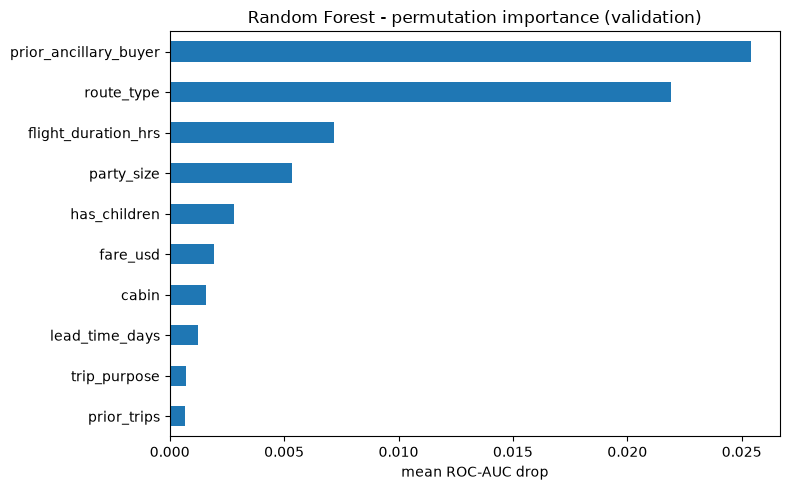

prior_ancillary_buyer    0.0254
route_type               0.0219
flight_duration_hrs      0.0072
party_size               0.0053
has_children             0.0028
fare_usd                 0.0019
cabin                    0.0016
lead_time_days           0.0012
trip_purpose             0.0007
prior_trips              0.0007
loyalty_tier             0.0005
destination_region       0.0004
device                   0.0002
departure_weekend        0.0001
channel                  0.0001
dtype: float64

In [18]:
perm = permutation_importance(rf, val[FEATURES], val[TARGET], n_repeats=5, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
perm_imp.head(10).plot(kind="barh", ax=ax); ax.invert_yaxis()
ax.set_title("Random Forest - permutation importance (validation)"); ax.set_xlabel("mean ROC-AUC drop")
plt.tight_layout(); plt.show()
perm_imp.round(4)

## 12. Calibration - the lesson carried over from the CTR project
A propensity score that feeds a revenue forecast must mean what it says: of bookings scored 0.40, about 40% should buy. Raw model probabilities often don't (the CTR project's were off by 14-29x by decile). So: check first, and if it is off, fix it with **Platt scaling fitted on the validation month** (never on test) and re-check on test. Below, the check comes first - and it decides whether the fix is even needed.

In [19]:
def calibration_table(y_true, p, bins=10) -> pd.DataFrame:
    d = pd.DataFrame({"y": y_true, "p": p})
    d["bin"] = pd.qcut(d["p"], bins, labels=False, duplicates="drop")
    return d.groupby("bin").agg(n=("y", "size"), mean_predicted=("p", "mean"), actual_rate=("y", "mean")).reset_index()

raw_test_p = selected.predict_proba(test[FEATURES])[:, 1]
cal_raw = calibration_table(test[TARGET].values, raw_test_p)
print("raw", SELECTED_NAME, "test Brier:", round(brier_score_loss(test[TARGET], raw_test_p), 4))
cal_raw.round(3)

raw Logistic Regression test Brier: 0.2236


,bin,n,mean_predicted,actual_rate
0,0,970,0.215,0.231
1,1,970,0.254,0.253
2,2,970,0.287,0.268
3,3,970,0.346,0.368
4,4,970,0.386,0.371
5,5,969,0.416,0.413
6,6,970,0.446,0.441
7,7,970,0.496,0.477
8,8,970,0.571,0.589
9,9,970,0.662,0.656


Platt-calibrated test Brier: 0.2237 | raw was: 0.2236


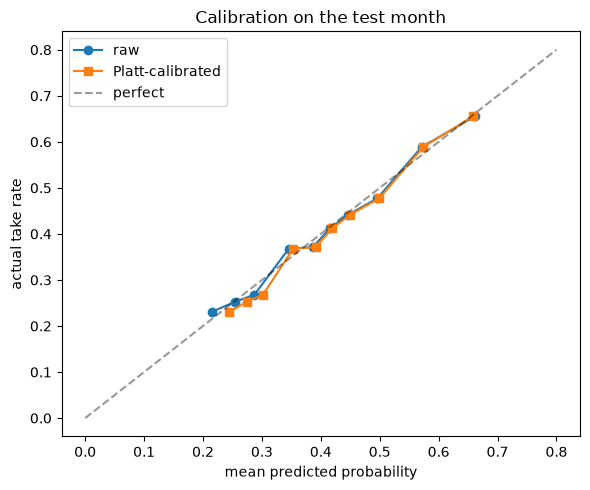

In [20]:
from sklearn.linear_model import LogisticRegression as Platt
val_p = selected.predict_proba(val[FEATURES])[:, 1].reshape(-1, 1)
platt = Platt().fit(val_p, val[TARGET])
test_p_cal = platt.predict_proba(raw_test_p.reshape(-1, 1))[:, 1]
print("Platt-calibrated test Brier:", round(brier_score_loss(test[TARGET], test_p_cal), 4),
      "| raw was:", round(brier_score_loss(test[TARGET], raw_test_p), 4))
cal_cal = calibration_table(test[TARGET].values, test_p_cal)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(cal_raw["mean_predicted"], cal_raw["actual_rate"], marker="o", label="raw")
ax.plot(cal_cal["mean_predicted"], cal_cal["actual_rate"], marker="s", label="Platt-calibrated")
ax.plot([0, 0.8], [0, 0.8], "k--", alpha=0.4, label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("actual take rate")
ax.set_title("Calibration on the test month"); ax.legend(); plt.tight_layout(); plt.show()

In [21]:
# Use the calibrated probabilities from here on - they are the ones a revenue number may multiply.
test = test.assign(score=test_p_cal)
print("calibrated score range on test:", round(test['score'].min(), 3), "to", round(test['score'].max(), 3))

calibrated score range on test: 0.187 to 0.794


## 13. Decile lift and cumulative gains (test month, calibrated scores)

In [22]:
ranked = test.sort_values("score", ascending=False).reset_index(drop=True)
ranked["decile"] = (np.arange(len(ranked)) * 10 // len(ranked)) + 1  # decile 1 = highest scores (frame is sorted desc)
deciles = ranked.groupby("decile").agg(
    bookings=("score", "size"), buyers=(TARGET, "sum"),
    mean_score=("score", "mean"), revenue=("ancillary_revenue_usd", "sum")).reset_index()
deciles["take_rate_pct"] = (deciles["buyers"] / deciles["bookings"] * 100).round(2)
base_rate = test[TARGET].mean()
deciles["lift"] = (deciles["buyers"] / deciles["bookings"] / base_rate).round(3)
deciles["cum_bookings_pct"] = (deciles["bookings"].cumsum() / len(ranked) * 100).round(2)
deciles["cum_buyers_pct"] = (deciles["buyers"].cumsum() / ranked[TARGET].sum() * 100).round(2)
deciles["cum_revenue_pct"] = (deciles["revenue"].cumsum() / ranked["ancillary_revenue_usd"].sum() * 100).round(2)
deciles.round(3)

,decile,bookings,buyers,mean_score,revenue,take_rate_pct,lift,cum_bookings_pct,cum_buyers_pct,cum_revenue_pct
0,1,970,636,0.659,38705,65.57,1.612,10.00,16.13,22.68
1,2,970,571,0.574,30298,58.87,1.448,20.00,30.60,40.43
2,3,970,463,0.499,20857,47.73,1.174,30.00,42.34,52.65
3,4,970,428,0.449,18469,44.12,1.085,40.00,53.19,63.47
4,5,970,400,0.420,15771,41.24,1.014,50.01,63.34,72.71
5,6,970,360,0.391,13557,37.11,0.913,60.01,72.46,80.65
6,7,970,358,0.353,11999,36.91,0.908,70.01,81.54,87.68
7,8,970,260,0.302,7599,26.80,0.659,80.01,88.13,92.14
8,9,970,244,0.274,7044,25.15,0.619,90.01,94.32,96.26
9,10,969,224,0.245,6378,23.12,0.568,100.00,100.00,100.00


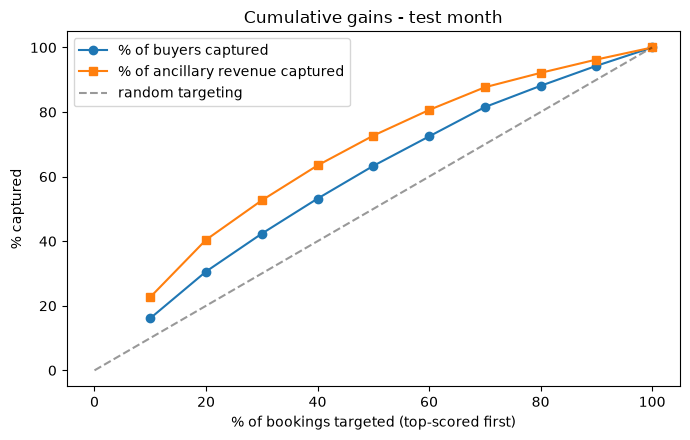

In [23]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(deciles["cum_bookings_pct"], deciles["cum_buyers_pct"], marker="o", label="% of buyers captured")
ax.plot(deciles["cum_bookings_pct"], deciles["cum_revenue_pct"], marker="s", label="% of ancillary revenue captured")
ax.plot([0, 100], [0, 100], "k--", alpha=0.4, label="random targeting")
ax.set_xlabel("% of bookings targeted (top-scored first)"); ax.set_ylabel("% captured")
ax.set_title("Cumulative gains - test month"); ax.legend(); plt.tight_layout(); plt.show()

## 14. Revenue simulation - what targeting is worth
Scenario: the offer push (promo placement + incentive) costs **$0.40 per booking shown the offer**. Showing it to everyone earns all the revenue but pays the cost on every booking; targeting the top deciles keeps most revenue and drops most cost. Non-targeted bookings are assumed to buy nothing in this scenario - stated plainly, this is an upper bound on targeting value, and section 16 says how a real team would measure the true increment.

In [24]:
PROMO_COST = 0.40
total_rev = ranked["ancillary_revenue_usd"].sum()
rows = []
for top_n in [1, 2, 3, 5, 10]:
    part = ranked[ranked["decile"] <= top_n]
    gross = part["ancillary_revenue_usd"].sum()
    cost = PROMO_COST * len(part)
    rows.append({"target": f"Top {top_n * 10}%", "offers": len(part), "buyers": int(part[TARGET].sum()),
                 "gross_revenue": round(gross, 0), "promo_cost": round(cost, 0),
                 "net_revenue": round(gross - cost, 0),
                 "revenue_share_pct": round(gross / total_rev * 100, 1),
                 "net_revenue_per_1000_offers": round((gross - cost) / len(part) * 1000, 0)})
strategies = pd.DataFrame(rows)
base_eff = strategies.loc[strategies["target"] == "Top 100%", "net_revenue_per_1000_offers"].iloc[0]
strategies["efficiency_vs_offer_all_pct"] = ((strategies["net_revenue_per_1000_offers"] / base_eff - 1) * 100).round(1)
print("Read this table on EFFICIENCY, not totals: offering to everyone always banks the most total")
print("revenue (the model cannot create buyers). Targeting wins per offer spent - and per customer")
print("spared the promo. The right depth is where efficiency is high AND revenue share is acceptable.")
strategies

Read this table on EFFICIENCY, not totals: offering to everyone always banks the most total
revenue (the model cannot create buyers). Targeting wins per offer spent - and per customer
spared the promo. The right depth is where efficiency is high AND revenue share is acceptable.


,target,offers,buyers,gross_revenue,promo_cost,net_revenue,revenue_share_pct,net_revenue_per_1000_offers,efficiency_vs_offer_all_pct
0,Top 10%,970,636,38705,388.0,38317.0,22.7,39502.0,129.7
1,Top 20%,1940,1207,69003,776.0,68227.0,40.4,35169.0,104.5
2,Top 30%,2910,1670,89860,1164.0,88696.0,52.6,30480.0,77.2
3,Top 50%,4850,2498,124100,1940.0,122160.0,72.7,25188.0,46.5
4,Top 100%,9699,3944,170677,3880.0,166797.0,100.0,17197.0,0.0


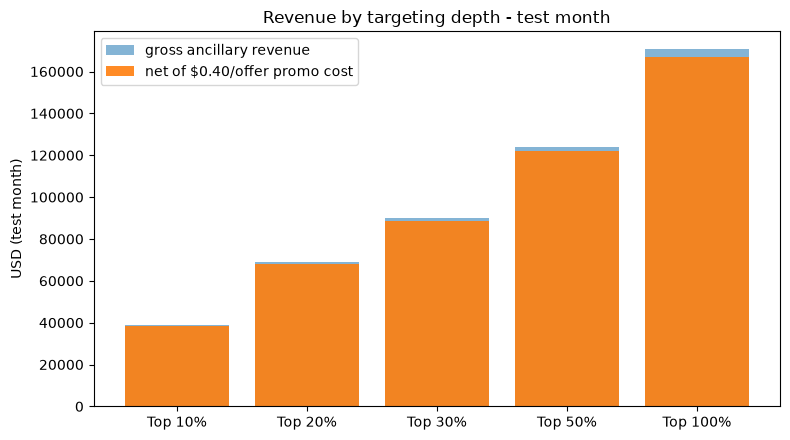

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(strategies["target"], strategies["gross_revenue"], alpha=0.55, label="gross ancillary revenue")
ax.bar(strategies["target"], strategies["net_revenue"], alpha=0.9, label="net of $0.40/offer promo cost")
ax.set_ylabel("USD (test month)"); ax.set_title("Revenue by targeting depth - test month"); ax.legend()
plt.tight_layout(); plt.show()

## 15. Product mix inside the targeted audience

In [26]:
top30 = ranked[ranked["decile"] <= 3]
for col in ["bought_insurance", "bought_seat_upgrade", "bought_extra_baggage"]:
    print(f"{col:22s} take rate in top 30%: {top30[col].mean() * 100:5.2f}%   vs all bookings: {test[col].mean() * 100:5.2f}%")

bought_insurance       take rate in top 30%: 30.52%   vs all bookings: 18.47%
bought_seat_upgrade    take rate in top 30%: 23.54%   vs all bookings: 15.06%
bought_extra_baggage   take rate in top 30%: 23.44%   vs all bookings: 17.31%


## 16. Limitations, and how this would really be deployed
- **Propensity is not uplift.** The model finds bookings likely to buy anyway; it does not prove the offer caused the purchase. The honest next step is an A/B test of the targeting strategy itself (targeted vs offer-all, revenue per booking as the primary metric), or an uplift model. The simulation in section 14 is an upper bound, not a measured increment.
- **Synthetic labels.** Purchases were drawn from the documented propensity model in `src/generate_data.py`. Effect sizes (which segments buy, how strongly history predicts) are properties of that model - the workflow, leakage discipline, calibration and revenue method are the deliverable.
- **Drift is visible already:** the take rate rises month to month as repeat buyers accumulate (section 5). A production score needs scheduled retraining and calibration monitoring.
- **Deployment shape:** score each booking at checkout from the same feature list in section 4; show the offer above a threshold chosen from the section 14 table (the decile where marginal net revenue turns thin); log score, offer shown, and outcome for the A/B readout.

## 17. Export the report tables

In [27]:
comparison_val.assign(split="validation").to_csv(REPORTS / "model_comparison_validation.csv")
test_scores.assign(split="test").to_csv(REPORTS / "model_comparison_test.csv")
deciles.to_csv(REPORTS / "decile_lift_test.csv", index=False)
strategies.to_csv(REPORTS / "targeting_strategies_test.csv", index=False)
cal_raw.assign(version="raw").to_csv(REPORTS / "calibration_raw_test.csv", index=False)
cal_cal.assign(version="platt_calibrated").to_csv(REPORTS / "calibration_calibrated_test.csv", index=False)
odds.rename("odds_ratio").to_csv(REPORTS / "lr_odds_ratios.csv")
perm_imp.rename("permutation_importance").to_csv(REPORTS / "rf_permutation_importance.csv")
print("exported:", sorted(p.name for p in REPORTS.glob('*.csv')))

exported: ['calibration_calibrated_test.csv', 'calibration_raw_test.csv', 'decile_lift_test.csv', 'lr_odds_ratios.csv', 'model_comparison_test.csv', 'model_comparison_validation.csv', 'rf_permutation_importance.csv', 'targeting_strategies_test.csv']
